# CAETEC - ARIMA y SARIMA

El objetivo de este notebook es pronosticar el indicador de posible cola de cada robot mediante modelos ARIMA y SARIMA, comparandolos con reglas sencillas. Para ello, definimos la etiqueta real con pct_posible_cola > 0.5 y trabajamos con bloques de 30 minutos. Nuestra variable objetivo es un indicador indirecto, no medimos directamente vacas esperando ni minutos de espera.

## 1. Preparación de datos

Cargamos el dataset limpio y conservamos el orden cronológico.

### 1.1 Librerías y configuración

Importamos las librerías para cargar datos, ajustar modelos, evaluar predicciones y realizar pruebas estadísticas.

In [ ]:
import sys
from pathlib import Path
from time import perf_counter
import gc
import warnings
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.kalman_filter import (
    MEMORY_NO_FILTERED,
    MEMORY_NO_GAIN,
    MEMORY_NO_PREDICTED_COV,
    MEMORY_NO_SMOOTHING,
)
from statsmodels.tsa.stattools import acf, adfuller, kpss
from threadpoolctl import threadpool_limits

Fijamos el umbral real, la frecuencia temporal y el formato de las salidas para todos los análisis.

In [ ]:
UMBRAL_REAL = 0.5
FRECUENCIA = "30min"
OBJETIVO = "pct_posible_cola"
_hilos = threadpool_limits(limits=1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.options.display.float_format = "{:.4g}".format

### 1.2 Carga del dataset
Cargamos el dataset a trabajar: dataset_final_serie_tiempo.parquet.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("Mount Colab")
    from google.colab import drive

    drive.mount("/content/drive")
    RUTA_DATOS = Path("/content/drive/My Drive/Datos/Procesado")
else:
    print("Running local")
    RUTA_DATOS = Path.cwd() / ".." / ".." / "data"
print(RUTA_DATOS)

Cargamos el parquet, convertimos las fechas y ordenamos los bloques por tiempo y robot.

In [ ]:
def load_dataset(file="dataset_final_serie_tiempo.parquet"):
    dataset_final = pd.read_parquet(Path(RUTA_DATOS) / file)
    dataset_final["bloque_tiempo"] = pd.to_datetime(dataset_final["bloque_tiempo"])
    dataset_final = dataset_final.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)
    print(f"dataset_final: {len(dataset_final):,} bloques x {dataset_final.shape[1]} columnas")
    print(list(dataset_final.columns))
    return dataset_final


datos_originales = load_dataset()

dataset_final: 179,850 bloques x 24 columnas
['ms', 'bloque_tiempo', 'total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'temporada', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola']


Cargamos 179,850 bloques y 24 columnas. Conservamos esta entrada para mantener comparables los resultados de las secciones siguientes.

### 1.3 Calendario compartido

Partimos del dataset limpio de las etapas anteriores y conservamos los bloques de 30 minutos, incluidos los que no tienen ordeños.
Aplicamos los cortes 70/15/15 por instante completo y usamos las mismas fechas para los tres robots. Construimos el calendario, las particiones compartidas y la etiqueta de posible cola con un umbral real de 0.5.
Clasificamos como positivo un valor mayor que 0.5 y como negativo un valor igual o menor que 0.5.

In [ ]:
def preparar_base(datos):
    base = datos.copy()
    base["bloque_tiempo"] = pd.to_datetime(base["bloque_tiempo"])
    base = base.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)
    fechas = pd.DatetimeIndex(base["bloque_tiempo"].unique()).sort_values()
    corte_train, corte_val = (int(len(fechas) * 0.7), int(len(fechas) * 0.85))
    inicio_val, inicio_test = (fechas[corte_train], fechas[corte_val])
    base["Conjunto"] = np.where(
        base["bloque_tiempo"] < inicio_val,
        "Entrenamiento",
        np.where(base["bloque_tiempo"] < inicio_test, "Validación", "Prueba"),
    )
    base["cola"] = base[OBJETIVO].gt(UMBRAL_REAL).astype(int)
    base["franja"] = base["bloque_tiempo"].dt.hour * 2 + base["bloque_tiempo"].dt.minute // 30
    base["dia_semana"] = base["bloque_tiempo"].dt.dayofweek
    base["mes"] = base["bloque_tiempo"].dt.to_period("M").astype(str)
    horarios = {f: f"{f // 2:02d}:{30 * (f % 2):02d}" for f in range(48)}
    base["Horario"] = base["franja"].map(horarios)
    resumen = (
        base.groupby("Conjunto")
        .agg(
            Registros=(OBJETIVO, "size"),
            Inicio=("bloque_tiempo", "min"),
            Fin=("bloque_tiempo", "max"),
            Frecuencia_cola_pct=("cola", lambda x: 100 * x.mean()),
        )
        .reindex(["Entrenamiento", "Validación", "Prueba"])
    )
    calendario = {
        "fechas": fechas,
        "fechas_train": fechas[:corte_train],
        "fechas_val": fechas[corte_train:corte_val],
        "fechas_test": fechas[corte_val:],
        "INICIO_VAL": inicio_val,
        "INICIO_TEST": inicio_test,
        "robots": sorted(base["ms"].unique()),
        "horarios": horarios,
        "resumen_particiones": resumen,
    }
    return (base, calendario)


base, calendario = preparar_base(datos_originales)

Conservamos las mismas fechas de corte y los identificadores de robot para las secciones siguientes.

In [ ]:
fechas = calendario["fechas"]
fechas_val = calendario["fechas_val"]
fechas_test = calendario["fechas_test"]
INICIO_VAL = calendario["INICIO_VAL"]
INICIO_TEST = calendario["INICIO_TEST"]
robots = calendario["robots"]
horarios = calendario["horarios"]

Mostramos el tamaño, las fechas y la frecuencia de posible cola de cada partición.

In [ ]:
display(calendario["resumen_particiones"].reset_index())

,Conjunto,Registros,Inicio,Fin,Frecuencia_cola_pct
0,Entrenamiento,125892,2022-08-01 00:00:00,2024-12-22 06:30:00,14.66
1,Validación,26979,2024-12-22 07:00:00,2025-06-27 15:00:00,42.54
2,Prueba,26979,2025-06-27 15:30:00,2025-12-31 23:30:00,57.53


Observamos que la frecuencia positiva sube de 14.66% en entrenamiento a 57.53% en prueba. Por eso comparamos con referencias simples y revisamos el desempeño por periodo.

Graficamos la posición cronológica de entrenamiento, validación y prueba para comprobar que no se superponen.

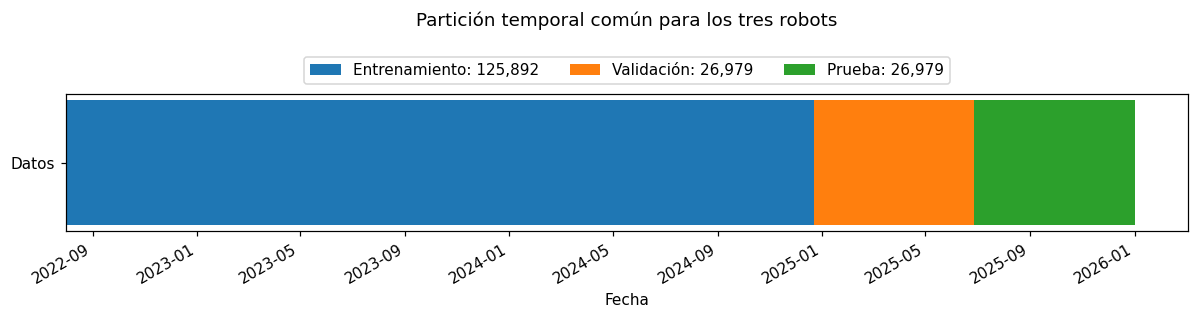

In [ ]:
def graficar_particiones(calendario):
    fig, ax = plt.subplots(figsize=(11, 3))
    for nombre, fila in calendario["resumen_particiones"].iterrows():
        duracion = fila["Fin"] - fila["Inicio"] + pd.Timedelta(FRECUENCIA)
        ax.barh("Datos", duracion, left=fila["Inicio"], label=f"{nombre}: {fila['Registros']:,}")
    ax.set_title("Partición temporal común para los tres robots", pad=45)
    ax.set_xlabel("Fecha")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3)
    fig.autofmt_xdate()
    fig.tight_layout()
    return fig


fig = graficar_particiones(calendario)
plt.show()
plt.close(fig)

Comprobamos que las particiones respetan el tiempo y comparten cortes entre robots. Conservamos este diseño para evaluar con el pasado disponible y evitar mezclar observaciones futuras.

## 2. ARIMA y SARIMA

Pronosticamos el siguiente bloque por robot y comparamos con persistencia, mismo bloque del día anterior y siempre cola.
Fijamos el umbral real en 0.5 y elegimos los umbrales predictivos con validación. Comparamos dos formas de pronosticar el indicador del siguiente bloque de 30 minutos.
Con ARIMA usamos la relación con el pasado reciente y con SARIMA añadimos una repetición diaria de 48 bloques.

### 2.1 Configuración y series por robot

Configuramos el ciclo diario, los cinco cortes de validación, los umbrales candidatos y el horizonte futuro.

In [ ]:
ESTACIONALIDAD = 48
N_CORTES = 5
META_F1 = 0.6
UMBRALES = np.linspace(0, 1, 101)
PASOS_FUTUROS = 4

Construimos una serie regular del indicador y otra de actividad para cada robot, sin inventar bloques anteriores a su inicio.

In [ ]:
def preparar_series(datos):
    """Construimos las series regulares de cada robot."""
    series = {}
    actividad = {}
    for robot, grupo in datos.groupby("ms", sort=True):
        grupo = grupo.set_index("bloque_tiempo").sort_index()
        series[robot] = grupo[OBJETIVO].astype(float).asfreq(FRECUENCIA)
        actividad[robot] = grupo["hubo_ordenios"].asfreq(FRECUENCIA)
    robots = sorted(series)
    inventario = datos.groupby("ms").agg(
        Bloques=(OBJETIVO, "size"),
        Inicio=("bloque_tiempo", "min"),
        Fin=("bloque_tiempo", "max"),
        Sin_ordenios=("hubo_ordenios", lambda s: s.eq(0).sum()),
    )
    return (series, actividad, robots, inventario)


series, actividad, robots, inventario = preparar_series(base)

Mostramos la cobertura temporal y el número de bloques sin ordeños de cada robot.

In [ ]:
display(inventario)

,Bloques,Inicio,Fin,Sin_ordenios
ms,,,,
VMS 1,59950,2022-08-01 01:00:00,2025-12-31 23:30:00,14975
VMS 2,59948,2022-08-01 02:00:00,2025-12-31 23:30:00,16777
VMS 3,59952,2022-08-01 00:00:00,2025-12-31 23:30:00,16040


Observamos que los robots comienzan en horas distintas y conservan bloques sin ordeños. Los modelamos por separado y no agregamos ceros anteriores a su inicio.

### 2.2 Diagnóstico temporal en entrenamiento

Revisamos cambios mensuales, horarios, estacionariedad y autocorrelación usando solo entrenamiento.
Contrastamos hipótesis distintas con ADF y KPSS y no decidimos la diferenciación con una sola prueba.
Llamamos rezago a la distancia hacia el pasado. Con bloques de 30 minutos, el rezago 1 equivale a media hora, el 48 a un día y el 336 a una semana.
Revisamos estos vínculos antes de elegir los modelos, sin usar el conjunto de prueba.

Graficamos la evolución mensual y el perfil horario del indicador continuo durante el entrenamiento.

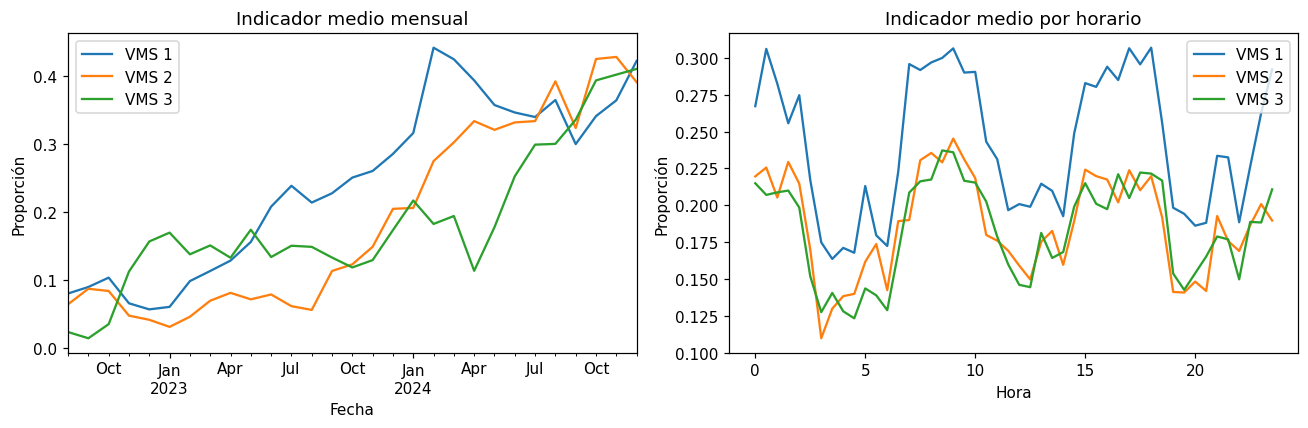

In [ ]:
def graficar_perfiles_entrenamiento(robots, series):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for robot in robots:
        y = series[robot].loc[lambda s: s.index < INICIO_VAL]
        y.resample("MS").mean().plot(ax=axes[0], label=robot)
        perfil = y.groupby(y.index.hour + y.index.minute / 60).mean()
        axes[1].plot(perfil.index, perfil, label=robot)
    axes[0].set(title="Indicador medio mensual", ylabel="Proporción", xlabel="Fecha")
    axes[1].set(title="Indicador medio por horario", xlabel="Hora", ylabel="Proporción")
    axes[0].legend()
    axes[1].legend()
    plt.tight_layout()
    return fig


fig = graficar_perfiles_entrenamiento(robots, series)
plt.show()
plt.close(fig)

Identificamos aumentos entre meses y perfiles horarios distintos por robot. Exploramos cambios de nivel y ciclos diarios mediante modelos separados.

Necesitamos revisar la estacionariedad, es decir, si el nivel, la variación y las relaciones temporales se mantienen aproximadamente estables.
Si detectamos cambios, probamos modelar diferencias entre bloques en lugar de trabajar solo con sus niveles.

In [ ]:
def diagnosticar_series(robots, series):
    diagnosticos = []
    for robot in robots:
        y = series[robot].loc[lambda s: s.index < INICIO_VAL]
        with warnings.catch_warnings(record=True) as avisos:
            adf = adfuller(y, maxlag=48, autolag="AIC")
            kps = kpss(y, regression="c", nlags="auto")
        correlaciones = acf(y, nlags=336, fft=True)
        diagnosticos.append(
            {
                "Robot": robot,
                "ADF_p": adf[1],
                "KPSS_p": kps[1],
                "ACF_1": correlaciones[1],
                "ACF_48": correlaciones[48],
                "ACF_336": correlaciones[336],
                "ACF_48_diferencia": acf(y.diff().dropna(), nlags=48, fft=True)[48],
                "Avisos": " | ".join((str(a.message) for a in avisos)),
            }
        )
    diagnostico = pd.DataFrame(diagnosticos)
    return diagnostico


diagnostico = diagnosticar_series(robots, series)

Antes de entrenar ARIMA y SARIMA, revisamos si el comportamiento de la serie cambia con el tiempo. Por ejemplo, distinguimos una serie que suele fluctuar cerca del 20% de otra que permanece un tiempo cerca del 20% y después cerca del 60%. Para revisarlo usamos dos pruebas que parten de ideas diferentes:


| Prueba | De qué idea partimos | Qué concluimos si p < 0.05 |
|---|---|---|
| ADF | Consideramos que los cambios pueden acumularse y alejar la serie de su nivel anterior. | Encontramos evidencia contra esa forma de inestabilidad, aunque todavía necesitamos revisar otros cambios. |
| KPSS | Consideramos que la serie fluctúa alrededor de un nivel estable. | Encontramos evidencia de que ese nivel no se mantiene estable. |

Usamos el valor p para decidir si cuestionamos la idea inicial de cada prueba. Por eso, un valor pequeño tiene una lectura diferente en cada una. Tomamos 0.05 como regla de decisión.

Si las pruebas no nos dan una conclusión clara, comparamos dos alternativas:

- Trabajamos con los valores originales del indicador.
- Trabajamos con el cambio entre un bloque y el anterior. Por ejemplo, si pasamos de 0.20 a 0.25, analizamos un aumento de 0.05. A esto lo llamamos diferenciar.

Después evaluamos ambas alternativas en validación y elegimos la que pronostica mejor.

Dentro de ADF también decidimos cuántos bloques anteriores considerar. Los llamamos rezagos y cada uno representa 30 minutos. Usamos AIC como una regla para incluir suficiente información del pasado sin añadir complejidad innecesaria.

In [ ]:
display(diagnostico.drop(columns="Avisos"))

,Robot,ADF_p,KPSS_p,ACF_1,ACF_48,ACF_336,ACF_48_diferencia
0,VMS 1,3.629e-13,0.01,0.1979,0.1885,0.1748,0.03153
1,VMS 2,1.13e-09,0.01,0.2404,0.2216,0.2153,0.01531
2,VMS 3,9.08e-15,0.01,0.1675,0.1551,0.1378,0.02547


Las pruebas no nos dan una conclusión clara sobre la estabilidad de la serie. Al analizar los cambios entre bloques, encontramos menor relación con el día anterior, por lo que comparamos modelos con valores originales (d = 0) y con diferencias (d = 1).

En KPSS, leemos 0.01 como un límite de la prueba y no necesariamente como un valor exacto.

Con ACF revisamos cuánto se relaciona el indicador actual con el de bloques anteriores. Por ejemplo, el rezago 1 corresponde a 30 minutos antes y el 48 al mismo horario del día anterior.

Con PACF revisamos esa relación descontando lo que ya explican los bloques intermedios. Así buscamos qué valores anteriores aportan información adicional.

Usamos ambas gráficas para decidir cuántos bloques pasados considerar en los modelos. Después comprobamos en validación si esa información mejora los pronósticos.

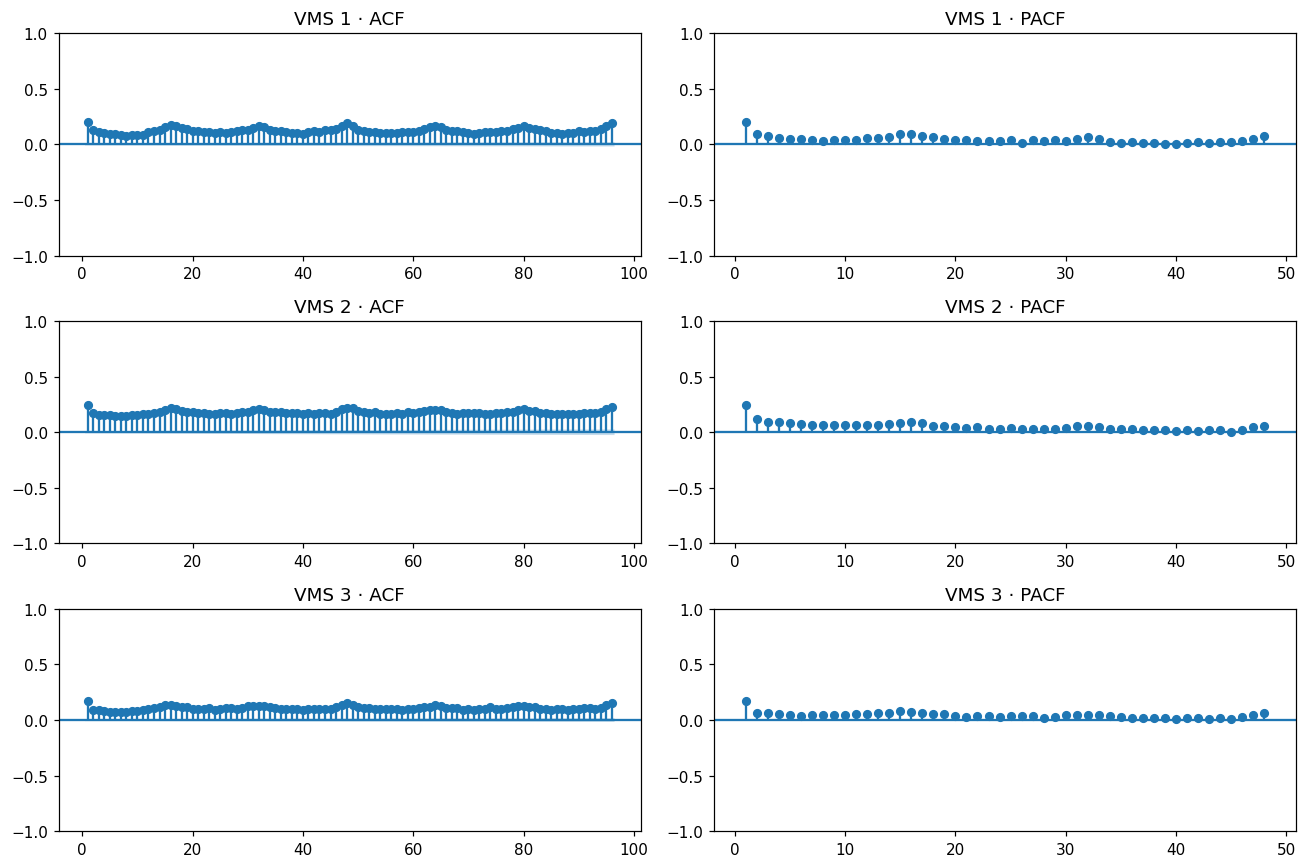

In [ ]:
def graficar_acf_pacf(robots, series):
    fig, axes = plt.subplots(len(robots), 2, figsize=(12, 8))
    for fila, robot in enumerate(robots):
        y = series[robot].loc[lambda s: s.index < INICIO_VAL]
        plot_acf(y, lags=96, zero=False, ax=axes[fila, 0], title=f"{robot} · ACF")
        plot_pacf(
            y, lags=48, zero=False, method="ywm", ax=axes[fila, 1], title=f"{robot} · PACF"
        )
    plt.tight_layout()
    return fig


fig = graficar_acf_pacf(robots, series)
plt.show()
plt.close(fig)

Observamos que el indicador se relaciona con los bloques recientes y mantiene relación con algunos valores más alejados. Por eso probamos ARIMA para aprovechar esa memoria y SARIMA para evaluar si añadir un ciclo diario de 48 bloques mejora los pronósticos.

Tomamos los picos fuera de las bandas como pistas de relación y comprobamos despues si podemos aprovecharlas para predecir mejor.

### 2.3 Normalización y validación temporal

Ajustamos cada escalador solo con el 70% inicial y lo mantenemos fijo. Usamos cinco ventanas consecutivas de validación.
Pronosticamos un bloque por vez y actualizamos el estado con el pasado observado.
Normalizamos para expresar cada serie en una escala comparable. Calculamos la media y la desviación solo con entrenamiento y después recuperamos la escala original.
Evitamos así usar información futura al preparar los datos.

In [ ]:
def escala_original(escaladores, valores, robot):
    return escaladores[robot].inverse_transform(np.asarray(valores).reshape(-1, 1)).ravel()

Ajustamos un escalador por robot usando solo entrenamiento y aplicamos esa transformación fija a toda su serie.

In [ ]:
def normalizar_series(robots, series):
    escaladores = {}
    series_z = {}
    for robot in robots:
        y = series[robot]
        escalador = StandardScaler().fit(y.loc[y.index < INICIO_VAL].to_numpy().reshape(-1, 1))
        escaladores[robot] = escalador
        series_z[robot] = pd.Series(
            escalador.transform(y.to_numpy().reshape(-1, 1)).ravel(),
            index=y.index,
            name=OBJETIVO,
        ).asfreq(FRECUENCIA)
    return (escaladores, series_z)


escaladores, series_z = normalizar_series(robots, series)

Mostramos las medias y desviaciones de entrenamiento utilizadas por los tres escaladores.

In [ ]:
display(
    pd.DataFrame(
        [
            {"Robot": r, "Media_train": e.mean_[0], "Desviacion_train": e.scale_[0]}
            for r, e in escaladores.items()
        ]
    )
)

,Robot,Media_train,Desviacion_train
0,VMS 1,0.2414,0.3491
1,VMS 2,0.1868,0.322
2,VMS 3,0.1831,0.314


Encontramos medias y desviaciones distintas entre robots. Conservamos un escalador de entrenamiento por serie para evitar incorporar información de validación o prueba.

Dividimos la validación en cinco ventanas consecutivas. En cada ventana entrenamos con todo el pasado disponible y pronosticamos un bloque por vez.
Después de cada bloque usamos lo observado para estimar el siguiente, sin volver a elegir parámetros en esa ventana.

In [ ]:
def construir_cortes(fechas, fechas_val):
    ventanas = [pd.DatetimeIndex(v) for v in np.array_split(fechas_val.to_numpy(), N_CORTES)]
    tabla_cortes = pd.DataFrame(
        [
            {
                "Corte": i,
                "Inicio_train": fechas[0],
                "Fin_train": ventana[0] - pd.Timedelta(FRECUENCIA),
                "Inicio_validacion": ventana[0],
                "Fin_validacion": ventana[-1],
                "Instantes_validacion": len(ventana),
            }
            for i, ventana in enumerate(ventanas, start=1)
        ]
    )
    return (ventanas, tabla_cortes)


ventanas, tabla_cortes = construir_cortes(fechas, fechas_val)

Presentamos las fechas de entrenamiento y validación de cada corte temporal.

In [ ]:
display(tabla_cortes)

,Corte,Inicio_train,Fin_train,Inicio_validacion,Fin_validacion,Instantes_validacion
0,1,2022-08-01,2024-12-22 06:30:00,2024-12-22 07:00:00,2025-01-28 18:00:00,1799
1,2,2022-08-01,2025-01-28 18:00:00,2025-01-28 18:30:00,2025-03-07 05:30:00,1799
2,3,2022-08-01,2025-03-07 05:30:00,2025-03-07 06:00:00,2025-04-13 17:00:00,1799
3,4,2022-08-01,2025-04-13 17:00:00,2025-04-13 17:30:00,2025-05-21 04:00:00,1798
4,5,2022-08-01,2025-05-21 04:00:00,2025-05-21 04:30:00,2025-06-27 15:00:00,1798


Comprobamos que usamos únicamente el pasado anterior a cada ventana. Con los cinco cortes comparamos candidatos bajo cambios temporales sin emitir todo el horizonte de una vez.

### 2.4 Funciones de ajuste, pronóstico y evaluación

Probamos cinco configuraciones ARIMA y cinco SARIMA por robot, con ciclo diario de 48 bloques.
Devolvemos las predicciones a la escala original y las limitamos a 0–1 para evaluar.
En ARIMA(p,d,q), usamos p para la memoria de valores pasados, d para las diferencias y q para la memoria de errores pasados.
En SARIMA añadimos (P,D,Q,s) para esas mismas ideas en un ciclo, con s = 48 bloques por día.

| Parámetro | Qué hacemos con él |
|---|---|
| p y P | Consideramos valores anteriores, cercanos o del ciclo diario. |
| d y D | Restamos valores anteriores para reducir cambios de nivel. |
| q y Q | Consideramos errores anteriores del pronóstico. |
| s | Fijamos la longitud del ciclo que queremos explorar. |

Probamos cinco configuraciones por familia. Incluimos d = 0 y d = 1 y mantenemos D = 0 en esta búsqueda acotada.

In [ ]:
CANDIDATOS = [
    {"Familia": "ARIMA", "Orden": (1, 0, 0), "Estacional": (0, 0, 0, 0)},
    {"Familia": "ARIMA", "Orden": (1, 0, 1), "Estacional": (0, 0, 0, 0)},
    {"Familia": "ARIMA", "Orden": (2, 0, 0), "Estacional": (0, 0, 0, 0)},
    {"Familia": "ARIMA", "Orden": (0, 1, 1), "Estacional": (0, 0, 0, 0)},
    {"Familia": "ARIMA", "Orden": (1, 1, 1), "Estacional": (0, 0, 0, 0)},
    {"Familia": "SARIMA", "Orden": (1, 0, 0), "Estacional": (1, 0, 0, 48)},
    {"Familia": "SARIMA", "Orden": (1, 0, 1), "Estacional": (1, 0, 0, 48)},
    {"Familia": "SARIMA", "Orden": (1, 0, 0), "Estacional": (0, 0, 1, 48)},
    {"Familia": "SARIMA", "Orden": (0, 1, 1), "Estacional": (1, 0, 0, 48)},
    {"Familia": "SARIMA", "Orden": (1, 1, 1), "Estacional": (1, 0, 0, 48)},
]
for candidato in CANDIDATOS:
    candidato["ID"] = f"{candidato['Familia']}{candidato['Orden']}{candidato['Estacional']}"
configuraciones = {c["ID"]: c for c in CANDIDATOS}

Mostramos los órdenes no estacionales y estacionales incluidos en la búsqueda.

In [ ]:
display(pd.DataFrame(CANDIDATOS).drop(columns="ID"))

,Familia,Orden,Estacional
0,ARIMA,"(1, 0, 0)","(0, 0, 0, 0)"
1,ARIMA,"(1, 0, 1)","(0, 0, 0, 0)"
2,ARIMA,"(2, 0, 0)","(0, 0, 0, 0)"
3,ARIMA,"(0, 1, 1)","(0, 0, 0, 0)"
4,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)"
5,SARIMA,"(1, 0, 0)","(1, 0, 0, 48)"
6,SARIMA,"(1, 0, 1)","(1, 0, 0, 48)"
7,SARIMA,"(1, 0, 0)","(0, 0, 1, 48)"
8,SARIMA,"(0, 1, 1)","(1, 0, 0, 48)"
9,SARIMA,"(1, 1, 1)","(1, 0, 0, 48)"


Exploramos diez configuraciones con y sin diferenciación y estacionalidad diaria. Elegimos la mejor dentro de esta búsqueda acotada y no la presentamos como un óptimo exhaustivo.

Comprobamos la convergencia para saber si el algoritmo terminó de encontrar un ajuste numérico estable.
Si no converge, evitamos comparar ese ajuste como si fuera válido.

In [ ]:
def convergio(resultado):
    detalles = resultado.fit_details
    if "arma_results" in detalles:
        return bool(detalles.converged and detalles.arma_results[-1].minimize_results.success)
    return bool(detalles.minimize_results.success)

Definimos el ajuste de cada candidato y un segundo optimizador de respaldo si el primero no converge.

In [ ]:
def ajustar_modelo(y, configuracion):
    inicio = perf_counter()
    mensajes = []
    for metodo, opciones in [
        ("L-BFGS-B", {"maxiter": 200, "ftol": 1e-09}),
        ("BFGS", {"maxiter": 250, "gtol": 0.0001}),
    ]:
        modelo = ARIMA(
            y,
            order=configuracion["Orden"],
            seasonal_order=configuracion["Estacional"],
            trend="c" if configuracion["Orden"][1] == 0 else "n",
            enforce_stationarity=True,
            enforce_invertibility=True,
        )
        modelo.ssm.set_conserve_memory(MEMORIA)
        with warnings.catch_warnings(record=True) as avisos:
            resultado = modelo.fit(
                method="innovations_mle",
                cov_type="none",
                method_kwargs={"minimize_kwargs": {"method": metodo, "options": opciones}},
            )
        mensajes.extend((str(a.message) for a in avisos))
        correcto = convergio(resultado) and np.isfinite(resultado.params).all()
        if correcto:
            break
    informacion = {
        "Convergio": bool(correcto),
        "Optimizador": metodo,
        "Segundos": perf_counter() - inicio,
        "Avisos": " | ".join(sorted(set(mensajes))),
    }
    return (resultado, informacion)

Reducimos la memoria que guarda el filtro, que es el mecanismo con el que actualizamos el pronóstico al llegar una observación.
Conservamos los estados necesarios para continuar la serie.

In [ ]:
MEMORIA = MEMORY_NO_PREDICTED_COV | MEMORY_NO_FILTERED | MEMORY_NO_GAIN | MEMORY_NO_SMOOTHING

Definimos cómo continuar el filtro con las nuevas observaciones de la serie.

In [ ]:
def continuar_filtro(resultado, nuevos):
    nuevos = nuevos.asfreq(FRECUENCIA)
    filtro = resultado.filter_results
    modelo = resultado.model.clone(nuevos)
    modelo.ssm.set_conserve_memory(MEMORIA)
    modelo.initialize_known(
        filtro.predicted_state[:, -1], filtro.predicted_state_cov[:, :, -1]
    )
    return modelo.filter(resultado.params, cov_type="none")

Pronosticamos cada bloque con la información anterior y después incorporamos el valor observado.
Limitamos el indicador estimado a 0–1, pero no lo tratamos como una probabilidad calibrada.

In [ ]:
def predecir_tramo(actividad, series, escaladores, resultado, nuevos, robot):
    actualizado = continuar_filtro(resultado, nuevos)
    crudas = escala_original(escaladores, actualizado.fittedvalues, robot)
    tabla = pd.DataFrame(
        {
            "bloque_tiempo": nuevos.index,
            "ms": robot,
            "Real": series[robot].loc[nuevos.index].to_numpy(),
            "Prediccion_sin_limitar": crudas,
            "Prediccion": np.clip(crudas, 0, 1),
            "hubo_ordenios": actividad[robot].loc[nuevos.index].to_numpy(),
        }
    )
    tabla["Cola_real"] = tabla["Real"].gt(UMBRAL_REAL).astype(int)
    return (tabla, actualizado)

Medimos tanto las etiquetas cola/no cola como el error del indicador continuo.
Comparamos siempre los modelos sobre los mismos bloques.

| Métrica | Qué revisamos |
|---|---|
| Precisión | Qué proporción de nuestras alertas corresponde a positivos reales. |
| Recall | Qué proporción de los positivos reales conseguimos detectar. |
| F1 | Cómo equilibramos precisión y recall. Buscamos valores altos. |
| MAE | Cuánto nos equivocamos en promedio en la escala del indicador. Buscamos valores bajos. |
| RMSE | Cuánto error cometemos dando más peso a fallos grandes. Buscamos valores bajos. |
| R² | Cómo se compara el error cuadrático con usar la media observada de prueba como referencia descriptiva. |

Con un MAE de 0.10 nos equivocamos, en promedio, diez puntos porcentuales del indicador.
Si obtenemos R² negativo, cometemos más error cuadrático que esa media de referencia.

In [ ]:
def evaluar(tabla):
    y, estimado = (tabla["Cola_real"], tabla["Cola_predicha"])
    resultado = {
        "N": len(tabla),
        "Prevalencia": y.mean(),
        "Pred_positivas": estimado.mean(),
        "Precision": precision_score(y, estimado, zero_division=0),
        "Recall": recall_score(y, estimado, zero_division=0),
        "F1": f1_score(y, estimado, zero_division=0),
    }
    if tabla["Prediccion"].notna().all():
        errores = tabla["Real"] - tabla["Prediccion"]
        resultado.update(
            MAE=mean_absolute_error(tabla["Real"], tabla["Prediccion"]),
            RMSE=np.sqrt(np.mean(errores**2)),
            R2=r2_score(tabla["Real"], tabla["Prediccion"]),
        )
    else:
        resultado.update(MAE=np.nan, RMSE=np.nan, R2=np.nan)
    return resultado

Distinguimos dos umbrales. Definimos la etiqueta real con indicador > 0.5 y elegimos en validación el corte de cada pronóstico que maximiza F1.
Mantenemos ese corte fijo en prueba, sin ajustarlo al ver los resultados.

In [ ]:
def elegir_umbral(tabla):
    opciones = [
        (f1_score(tabla["Cola_real"], tabla["Prediccion"].ge(u), zero_division=0), u)
        for u in UMBRALES
    ]
    return min(opciones, key=lambda par: (-par[0], abs(par[1] - 0.5), par[1]))[1]

### 2.5 Entrenamiento y selección con validación

Ajustamos cada candidato en los cinco cortes y conservamos sus predicciones solo si todos los cortes convergen.

In [ ]:
def validar_candidatos(robots, series_z, ventanas, actividad, series, escaladores):
    """Evaluamos los candidatos en los cinco cortes cronológicos."""
    predicciones_validacion = {}
    registro_ajustes = []
    for robot in robots:
        y = series_z[robot]
        for candidato in CANDIDATOS:
            partes = []
            for numero, ventana in enumerate(ventanas, start=1):
                historico = y.loc[y.index < ventana[0]]
                try:
                    resultado, info = ajustar_modelo(historico, candidato)
                    registro_ajustes.append(
                        {"Robot": robot, "ID": candidato["ID"], "Corte": numero, **info}
                    )
                    if info["Convergio"]:
                        tabla, _ = predecir_tramo(
                            actividad, series, escaladores, resultado, y.loc[ventana], robot
                        )
                        tabla["Corte"] = numero
                        partes.append(tabla)
                except (ValueError, np.linalg.LinAlgError) as error:
                    registro_ajustes.append(
                        {
                            "Robot": robot,
                            "ID": candidato["ID"],
                            "Corte": numero,
                            "Convergio": False,
                            "Segundos": np.nan,
                            "Avisos": str(error),
                        }
                    )
            if len(partes) == N_CORTES:
                predicciones_validacion[robot, candidato["ID"]] = pd.concat(
                    partes, ignore_index=True
                )
    log_ajustes = pd.DataFrame(registro_ajustes)
    return (predicciones_validacion, log_ajustes)


predicciones_validacion, log_ajustes = validar_candidatos(
    robots, series_z, ventanas, actividad, series, escaladores
)

Resumimos cuántos ajustes convergieron por robot y cuánto tiempo requirió la búsqueda.

In [ ]:
display(
    log_ajustes.groupby("Robot")
    .agg(
        Ajustes=("Convergio", "size"),
        Convergentes=("Convergio", "sum"),
        Segundos=("Segundos", "sum"),
    )
    .reset_index()
)

,Robot,Ajustes,Convergentes,Segundos
0,VMS 1,50,49,126.3
1,VMS 2,50,50,124
2,VMS 3,50,50,124.4


Comprobamos que convergen 149 de 150 ajustes. Excluimos un candidato de VMS 1 que no completa todos los cortes para evitar compararlo como si estuviera correctamente ajustado.

Elegimos un umbral por candidato y seleccionamos la mejor configuración de cada familia y robot con validación.

In [ ]:
def seleccionar_configuraciones(configuraciones, predicciones_validacion, robots):
    filas_validacion = []
    for (robot, identificador), tabla in predicciones_validacion.items():
        umbral = elegir_umbral(tabla)
        tabla["Cola_predicha"] = tabla["Prediccion"].ge(umbral).astype(int)
        candidato = configuraciones[identificador]
        filas_validacion.append(
            {
                "Robot": robot,
                "Familia": candidato["Familia"],
                "ID": identificador,
                "Orden": candidato["Orden"],
                "Estacional": candidato["Estacional"],
                "Umbral": umbral,
                **evaluar(tabla),
            }
        )
    comparacion_val = pd.DataFrame(filas_validacion).sort_values(
        ["Robot", "Familia", "F1", "RMSE", "MAE", "ID"],
        ascending=[True, True, False, True, True, True],
    )
    seleccion = (
        comparacion_val.groupby(["Robot", "Familia"], sort=False)
        .head(1)
        .reset_index(drop=True)
    )
    if len(seleccion) != 2 * len(robots):
        raise RuntimeError(
            "Alguna familia no tiene una configuración válida. Revisa log_ajustes."
        )
    return (comparacion_val, seleccion)


comparacion_val, seleccion = seleccionar_configuraciones(
    configuraciones, predicciones_validacion, robots
)

Comparamos todos los candidatos válidos por F1 y errores continuos, sin usar prueba.

In [ ]:
display(
    comparacion_val[["Robot", "Familia", "Orden", "Estacional", "Umbral", "F1", "MAE", "RMSE"]]
)

,Robot,Familia,Orden,Estacional,Umbral,F1,MAE,RMSE
4,VMS 1,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",0.35,0.5756,0.3318,0.3805
3,VMS 1,ARIMA,"(0, 1, 1)","(0, 0, 0, 0)",0.37,0.5756,0.3368,0.3843
1,VMS 1,ARIMA,"(1, 0, 1)","(0, 0, 0, 0)",0.37,0.5756,0.337,0.3844
2,VMS 1,ARIMA,"(2, 0, 0)","(0, 0, 0, 0)",0.17,0.5756,0.3526,0.4085
0,VMS 1,ARIMA,"(1, 0, 0)","(0, 0, 0, 0)",0.19,0.5756,0.3561,0.4128
6,VMS 1,SARIMA,"(1, 0, 0)","(0, 0, 1, 48)",0.2,0.5847,0.3494,0.4054
8,VMS 1,SARIMA,"(1, 1, 1)","(1, 0, 0, 48)",0.38,0.5815,0.3288,0.3776
7,VMS 1,SARIMA,"(0, 1, 1)","(1, 0, 0, 48)",0.37,0.5765,0.3328,0.3806
5,VMS 1,SARIMA,"(1, 0, 1)","(1, 0, 0, 48)",0.37,0.5758,0.3329,0.3806
13,VMS 2,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",0.38,0.6305,0.3265,0.3778


Encontramos candidatos con F1 similares y errores continuos distintos. Usamos RMSE y MAE para desempatar y evitar elegir únicamente por complejidad.

Mostramos los seis modelos seleccionados y los umbrales predictivos que quedarán fijados.

In [ ]:
display(seleccion[["Robot", "Familia", "Orden", "Estacional", "Umbral", "F1", "RMSE"]])

,Robot,Familia,Orden,Estacional,Umbral,F1,RMSE
0,VMS 1,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",0.35,0.5756,0.3805
1,VMS 1,SARIMA,"(1, 0, 0)","(0, 0, 1, 48)",0.2,0.5847,0.4054
2,VMS 2,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",0.38,0.6305,0.3778
3,VMS 2,SARIMA,"(1, 0, 0)","(1, 0, 0, 48)",0.15,0.645,0.4147
4,VMS 3,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",0.37,0.587,0.3849
5,VMS 3,SARIMA,"(1, 0, 0)","(1, 0, 0, 48)",0.18,0.601,0.4219


Seleccionamos ARIMA(1,1,1) para los tres robots y configuraciones SARIMA y umbrales diferentes. Fijamos los seis modelos antes de evaluar prueba.

Reunimos las predicciones de validación por familia, calculamos métricas globales y elegimos la familia por F1.

In [ ]:
def comparar_familias_validacion(predicciones_validacion, seleccion):
    pred_val_finales = []
    metricas_cortes = []
    for fila in seleccion.to_dict("records"):
        tabla = predicciones_validacion[fila["Robot"], fila["ID"]].copy()
        tabla["Modelo"] = fila["Familia"]
        pred_val_finales.append(tabla)
        for corte, grupo in tabla.groupby("Corte"):
            metricas_cortes.append(
                {
                    "Robot": fila["Robot"],
                    "Modelo": fila["Familia"],
                    "Corte": corte,
                    **evaluar(grupo),
                }
            )
    val_elegidos = pd.concat(pred_val_finales, ignore_index=True)
    resumen_val = pd.DataFrame(
        [
            {"Modelo": nombre, **evaluar(grupo)}
            for nombre, grupo in val_elegidos.groupby("Modelo")
        ]
    )
    FAMILIA_ELEGIDA = resumen_val.sort_values(
        ["F1", "RMSE", "Modelo"], ascending=[False, True, True]
    ).iloc[0]["Modelo"]
    return (metricas_cortes, resumen_val, FAMILIA_ELEGIDA)


metricas_cortes, resumen_val, FAMILIA_ELEGIDA = comparar_familias_validacion(
    predicciones_validacion, seleccion
)

Mostramos la comparación global de ARIMA y SARIMA en validación usando los bloques de los tres robots.

In [ ]:
display(resumen_val)

,Modelo,N,Prevalencia,Pred_positivas,Precision,Recall,F1,MAE,RMSE,R2
0,ARIMA,26979,0.4254,0.9701,0.4297,0.98,0.5975,0.3308,0.3811,0.0386
1,SARIMA,26979,0.4254,0.8441,0.4594,0.9116,0.6109,0.3536,0.414,-0.135


Obtenemos F1 global de validación de 0.6109 con SARIMA y 0.5975 con ARIMA. Elegimos SARIMA conforme al criterio F1 y reconocemos su mayor error continuo.

Desglosamos la evaluación de validación por robot y corte para revisar estabilidad temporal.

In [ ]:
display(pd.DataFrame(metricas_cortes)[["Robot", "Modelo", "Corte", "F1", "MAE", "RMSE"]])

,Robot,Modelo,Corte,F1,MAE,RMSE
0,VMS 1,ARIMA,1,0.5314,0.3455,0.3902
1,VMS 1,ARIMA,2,0.5302,0.3368,0.3818
2,VMS 1,ARIMA,3,0.5212,0.329,0.3754
3,VMS 1,ARIMA,4,0.6094,0.3285,0.3803
4,VMS 1,ARIMA,5,0.6731,0.3193,0.3747
5,VMS 1,SARIMA,1,0.5316,0.354,0.4112
6,VMS 1,SARIMA,2,0.5318,0.3464,0.4015
7,VMS 1,SARIMA,3,0.5326,0.3351,0.3912
8,VMS 1,SARIMA,4,0.6226,0.3523,0.4073
9,VMS 1,SARIMA,5,0.682,0.3592,0.4153


Observamos cambios de F1 entre cortes y robots, con aumentos en varios cortes finales. Conservamos el desglose para no presentar el desempeño como constante.

### 2.6 Ajuste final y verificación del filtro

Reajustamos los seis modelos con entrenamiento y validación. Comprobamos el pronóstico secuencial
y verificamos que los datos posteriores no alteren predicciones anteriores.

Reajustamos las seis configuraciones seleccionadas con entrenamiento y validación, manteniendo los escaladores originales.

In [ ]:
def ajustar_modelos_finales(configuraciones, seleccion, series_z):
    modelos_finales = {}
    ajustes_finales = []
    for fila in seleccion.to_dict("records"):
        robot, familia = (fila["Robot"], fila["Familia"])
        y = series_z[robot].loc[lambda s: s.index < INICIO_TEST]
        resultado, info = ajustar_modelo(y, configuraciones[fila["ID"]])
        if not info["Convergio"]:
            raise RuntimeError(
                f"No logramos convergencia en el ajuste final de {familia} en {robot}."
            )
        modelos_finales[familia, robot] = {
            "resultado": resultado,
            "umbral": float(fila["Umbral"]),
            "configuracion": configuraciones[fila["ID"]],
        }
        ajustes_finales.append({"Robot": robot, "Modelo": familia, **info})
    return (modelos_finales, ajustes_finales)


modelos_finales, ajustes_finales = ajustar_modelos_finales(
    configuraciones, seleccion, series_z
)

Mostramos convergencia, optimizador y duración de los ajustes finales anteriores a prueba.

In [ ]:
display(pd.DataFrame(ajustes_finales).drop(columns="Avisos"))

,Robot,Modelo,Convergio,Optimizador,Segundos
0,VMS 1,ARIMA,True,L-BFGS-B,0.3932
1,VMS 1,SARIMA,True,L-BFGS-B,9.39
2,VMS 2,ARIMA,True,L-BFGS-B,0.5402
3,VMS 2,SARIMA,True,L-BFGS-B,1.474
4,VMS 3,ARIMA,True,L-BFGS-B,0.4744
5,VMS 3,SARIMA,True,L-BFGS-B,1.446


Confirmamos que convergen los seis ajustes finales. Continuamos con prueba sin volver a seleccionar configuraciones ni umbrales con sus resultados.

Verificamos que el filtro reproduzca el pronóstico secuencial y que datos posteriores no alteren predicciones anteriores.

In [ ]:
def verificar_filtro(modelos_finales, series_z):
    verificaciones = []
    for (familia, robot), paquete in modelos_finales.items():
        y = series_z[robot].loc[lambda s: s.index < INICIO_TEST]
        configuracion = paquete["configuracion"]
        referencia = ARIMA(
            y.iloc[:-96],
            order=configuracion["Orden"],
            seasonal_order=configuracion["Estacional"],
            trend="c" if configuracion["Orden"][1] == 0 else "n",
        )
        referencia.ssm.set_conserve_memory(MEMORIA)
        referencia = referencia.filter(paquete["resultado"].params, cov_type="none")
        ventana = y.iloc[-96:]
        normal = continuar_filtro(referencia, ventana)
        alterada = ventana.copy()
        alterada.iloc[48:] += 10
        perturbada = continuar_filtro(referencia, alterada)
        np.testing.assert_allclose(
            normal.fittedvalues.iloc[0], referencia.forecast(1).iloc[0], atol=1e-07
        )
        np.testing.assert_allclose(
            normal.fittedvalues.iloc[:48], perturbada.fittedvalues.iloc[:48], atol=1e-07
        )
        estado_filtro = referencia
        secuencial = []
        for i in range(8):
            secuencial.append(estado_filtro.forecast(1).iloc[0])
            estado_filtro = continuar_filtro(estado_filtro, ventana.iloc[i : i + 1])
        np.testing.assert_allclose(normal.fittedvalues.iloc[:8], secuencial, atol=1e-07)
        verificaciones.append({"Modelo": familia, "Robot": robot, "Filtro_causal": True})
    return verificaciones


verificaciones = verificar_filtro(modelos_finales, series_z)

Mostramos si las comprobaciones del filtro se cumplieron en cada familia y robot.

In [ ]:
display(pd.DataFrame(verificaciones))

,Modelo,Robot,Filtro_causal
0,ARIMA,VMS 1,True
1,SARIMA,VMS 1,True
2,ARIMA,VMS 2,True
3,SARIMA,VMS 2,True
4,ARIMA,VMS 3,True
5,SARIMA,VMS 3,True


Superamos las seis comprobaciones del filtro. Respaldamos así la implementación a un paso, aunque seguimos suponiendo disponible el indicador del bloque anterior.

### 2.7 Evaluación en prueba y referencias

Mantenemos fijos parámetros y umbrales y actualizamos solo el estado con observaciones disponibles.
Evaluamos F1 > 0.60 y comparamos también con las tres referencias.

Comparamos con persistencia, que repite el bloque anterior del mismo robot, con el mismo bloque del día anterior y con siempre cola.
Usamos estas referencias para decidir si el modelo aporta algo frente a reglas sencillas.

In [ ]:
def predecir_prueba(
    fechas_test, modelos_finales, series_z, actividad, series, escaladores
):
    partes_test = []
    estados_actualizados = {}
    for (familia, robot), paquete in modelos_finales.items():
        tabla, actualizado = predecir_tramo(
            actividad,
            series,
            escaladores,
            paquete["resultado"],
            series_z[robot].loc[fechas_test],
            robot,
        )
        tabla["Modelo"] = familia
        tabla["Umbral"] = paquete["umbral"]
        tabla["Cola_predicha"] = tabla["Prediccion"].ge(paquete["umbral"]).astype(int)
        partes_test.append(tabla)
        estados_actualizados[familia, robot] = {**paquete, "resultado": actualizado}
    pred_test = pd.concat(partes_test, ignore_index=True)
    return (pred_test, estados_actualizados)


pred_test, estados_actualizados = predecir_prueba(
    fechas_test, modelos_finales, series_z, actividad, series, escaladores
)

#### Cómo calculamos la métrica global por familia

Entrenamos un modelo por robot y reunimos sus 8,993 predicciones de prueba para evaluar 26,979 bloques.
Calculamos un resultado para ARIMA y otro para SARIMA y no promediamos directamente los tres F1.

| Métrica global | Cómo la calculamos |
|---|---|
| Precisión, recall y F1 | Sumamos los aciertos y errores de los tres robots y aplicamos la fórmula a los totales de la clase positiva. |
| MAE | Promediamos los errores absolutos de todos los bloques y ponderamos cada robot por su cantidad de bloques. |
| RMSE | Promediamos los errores al cuadrado y después tomamos la raíz. No promediamos los RMSE individuales. |
| R² | Recalculamos con todos los valores observados y predichos y la media global del indicador. No promediamos los R² por robot. |

Para F1, sumamos verdaderos positivos (VP), falsas alarmas (FP) y omisiones (FN) de las tres máquinas:

$$F1_{\mathrm{global}}=\frac{2\sum_r VP_r}{2\sum_r VP_r+\sum_r FP_r+\sum_r FN_r}.$$

En SARIMA sumamos 14,883 VP, 9,756 FP y 639 FN y obtenemos F1 global = 0.7412.
Si promediáramos los tres F1 por robot obtendríamos aproximadamente 0.7400, por lo que distinguimos ambos resúmenes.

Como evaluamos igual número de bloques por robot, obtenemos el mismo MAE global que al promediar sus MAE.
No aplicamos esa equivalencia a F1, precisión, recall, RMSE ni R² y conservamos el desglose por robot.

En validación también reunimos las predicciones de los cinco cortes de cada configuración seleccionada por robot.
Usamos las métricas por corte para diagnosticar estabilidad y no las promediamos como F1 global.

Construimos las tres referencias y recalculamos las métricas de cada aproximación sobre todos sus bloques de prueba.

In [ ]:
def evaluar_prueba(actividad, fechas_test, pred_test, robots, series):
    referencias = []
    for robot in robots:
        y = series[robot]
        real = y.loc[fechas_test]
        for nombre, rezago in [
            ("Persistencia", 1),
            ("Mismo bloque ayer", 48),
            ("Siempre cola", None),
        ]:
            tabla = pd.DataFrame(
                {
                    "bloque_tiempo": fechas_test,
                    "ms": robot,
                    "Modelo": nombre,
                    "Real": real.to_numpy(),
                    "Cola_real": real.gt(UMBRAL_REAL).astype(int).to_numpy(),
                    "hubo_ordenios": actividad[robot].loc[fechas_test].to_numpy(),
                }
            )
            tabla["Prediccion"] = (
                y.shift(rezago).loc[fechas_test].to_numpy() if rezago else np.nan
            )
            tabla["Cola_predicha"] = (
                tabla["Prediccion"].gt(UMBRAL_REAL).astype(int) if rezago else 1
            )
            referencias.append(tabla)
    referencias_test = pd.concat(referencias, ignore_index=True)
    evaluacion_test = pd.concat([pred_test, referencias_test], ignore_index=True)
    resultados_globales = pd.DataFrame(
        [
            {"Modelo": nombre, **evaluar(grupo)}
            for nombre, grupo in evaluacion_test.groupby("Modelo")
        ]
    )
    f1_base = resultados_globales.set_index("Modelo").loc["Persistencia", "F1"]
    f1_siempre = resultados_globales.set_index("Modelo").loc["Siempre cola", "F1"]
    resultados_globales["Delta_F1_base"] = resultados_globales["F1"] - f1_base
    resultados_globales["Supera_0_60"] = resultados_globales["F1"].gt(META_F1)
    resultados_globales["Supera_siempre_cola"] = resultados_globales["F1"].gt(f1_siempre)
    resultados_globales["Elegido_en_validacion"] = resultados_globales["Modelo"].eq(
        FAMILIA_ELEGIDA
    )
    return (evaluacion_test, resultados_globales)


evaluacion_test, resultados_globales = evaluar_prueba(
    actividad, fechas_test, pred_test, robots, series
)

Presentamos la comparación global de precisión, recall, F1, MAE, RMSE y R² para las cinco aproximaciones.
Dejamos vacíos los errores continuos de siempre cola porque esa referencia emite únicamente una etiqueta.

In [ ]:
metricas = (
    resultados_globales.set_index("Modelo")
    .loc[
        ["Persistencia", "ARIMA", "SARIMA", "Mismo bloque ayer", "Siempre cola"],
        ["Precision", "Recall", "F1", "MAE", "RMSE", "R2"],
    ]
    .rename(columns={"Precision": "Precisión", "R2": "R²"})
)
display(metricas.fillna("—"))

,Precisión,Recall,F1,MAE,RMSE,R²
Modelo,,,,,,
Persistencia,0.6674,0.6674,0.6674,0.3383,0.462,-0.42
ARIMA,0.5753,1,0.7304,0.3179,0.3733,0.07297
SARIMA,0.604,0.9588,0.7412,0.3728,0.4283,-0.2208
Mismo bloque ayer,0.6503,0.6488,0.6496,0.3397,0.4723,-0.4841
Siempre cola,0.5753,1,0.7304,—,—,—


Obtenemos F1 = 0.7412 con SARIMA, solo 0.0107 por encima de siempre cola, y el mismo F1 de esa referencia con ARIMA. No declaramos utilidad suficiente por superar 0.60.

Recalculamos métricas por robot y por actividad para identificar diferencias que el resumen global puede ocultar.

In [ ]:
def desglosar_resultados(evaluacion_test):
    resultados_robot = pd.DataFrame(
        [
            {"Modelo": modelo, "Robot": robot, **evaluar(grupo)}
            for (modelo, robot), grupo in evaluacion_test.groupby(["Modelo", "ms"])
        ]
    )
    resultados_actividad = pd.DataFrame(
        [
            {
                "Modelo": modelo,
                "Actividad": "Con ordeños" if hubo else "Sin ordeños",
                **evaluar(grupo),
            }
            for (modelo, hubo), grupo in evaluacion_test.groupby(["Modelo", "hubo_ordenios"])
        ]
    )
    resultados_robot["Supera_0_60"] = resultados_robot["F1"].gt(META_F1)
    return (resultados_robot, resultados_actividad)


resultados_robot, resultados_actividad = desglosar_resultados(evaluacion_test)

Mostramos el desempeño individual de los tres robots y su número de bloques evaluados.

In [ ]:
display(resultados_robot)

,Modelo,Robot,N,Prevalencia,Pred_positivas,Precision,Recall,F1,MAE,RMSE,R2,Supera_0_60
0,ARIMA,VMS 1,8993,0.6307,1,0.6307,1,0.7735,0.312,0.3683,0.07626,True
1,ARIMA,VMS 2,8993,0.5674,1,0.5674,1,0.724,0.3196,0.3742,0.06693,True
2,ARIMA,VMS 3,8993,0.5279,1,0.5279,1,0.691,0.322,0.3772,0.04863,True
3,Mismo bloque ayer,VMS 1,8993,0.6307,0.6284,0.7016,0.699,0.7003,0.3184,0.4583,-0.4308,True
4,Mismo bloque ayer,VMS 2,8993,0.5674,0.5667,0.6407,0.6398,0.6403,0.345,0.4746,-0.5012,True
5,Mismo bloque ayer,VMS 3,8993,0.5279,0.527,0.5995,0.5985,0.599,0.3558,0.4835,-0.5629,False
6,Persistencia,VMS 1,8993,0.6307,0.6307,0.7086,0.7086,0.7086,0.3255,0.4564,-0.419,True
7,Persistencia,VMS 2,8993,0.5674,0.5674,0.6725,0.6725,0.6725,0.3337,0.4547,-0.378,True
8,Persistencia,VMS 3,8993,0.5279,0.528,0.6127,0.6128,0.6127,0.3557,0.4745,-0.5048,True
9,SARIMA,VMS 1,8993,0.6307,0.9392,0.6492,0.9667,0.7767,0.3926,0.4439,-0.3421,True


Encontramos mayor F1 en VMS 1 que en VMS 3. Conservamos el reporte por robot para evitar que el resultado global oculte diferencias entre máquinas.

Comparamos el desempeño en bloques con y sin ordeños, conservando la evaluación principal completa.

In [ ]:
display(resultados_actividad)

,Modelo,Actividad,N,Prevalencia,Pred_positivas,Precision,Recall,F1,MAE,RMSE,R2
0,ARIMA,Sin ordeños,3061,0,1,0,0,0,0.5494,0.5542,0
1,ARIMA,Con ordeños,23918,0.649,1,0.649,1,0.7871,0.2883,0.3433,0.009892
2,Mismo bloque ayer,Sin ordeños,3061,0,0.2506,0,0,0,0.2603,0.4729,0
3,Mismo bloque ayer,Con ordeños,23918,0.649,0.6154,0.6842,0.6488,0.666,0.3499,0.4722,-0.8732
4,Persistencia,Sin ordeños,3061,0,0.2431,0,0,0,0.2658,0.4023,0
5,Persistencia,Con ordeños,23918,0.649,0.6179,0.701,0.6674,0.6838,0.3476,0.469,-0.8484
6,SARIMA,Sin ordeños,3061,0,0.7109,0,0,0,0.2507,0.2633,0
7,SARIMA,Con ordeños,23918,0.649,0.9392,0.6626,0.9588,0.7836,0.3885,0.4451,-0.6642
8,Siempre cola,Sin ordeños,3061,0,1,0,0,0,NaN,NaN,NaN
9,Siempre cola,Con ordeños,23918,0.649,1,0.649,1,0.7871,NaN,NaN,NaN


Observamos mayor prevalencia y un F1 diferente al considerar solo bloques con ordeños. Lo tratamos como revisión retrospectiva y no suponemos conocida la actividad futura para mejorar la evaluación.

Leemos la matriz de confusión como un conteo de aciertos y errores. Distinguimos falsas alarmas de colas que no detectamos.
Consideramos ambos errores antes de decidir si las alertas serían útiles.

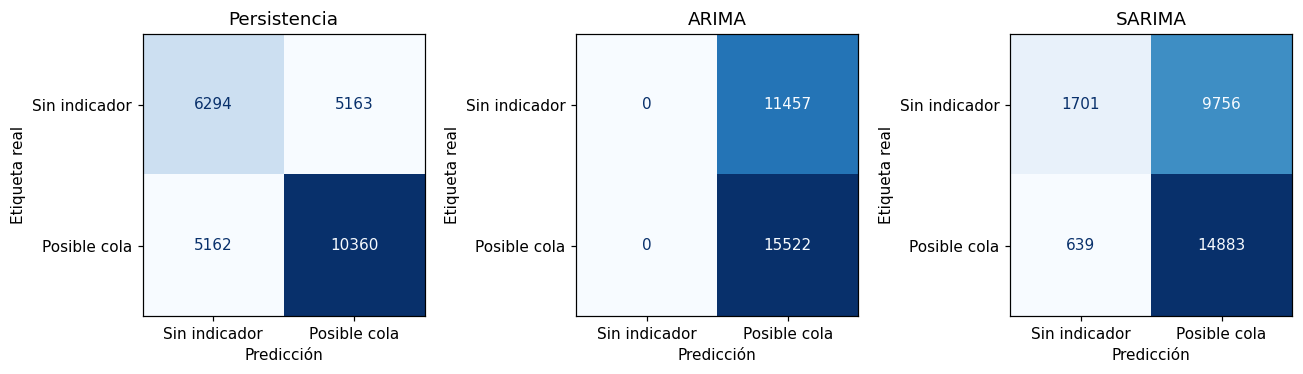

In [ ]:
def graficar_matrices_confusion(evaluacion_test):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    for ax, nombre in zip(axes, ["Persistencia", "ARIMA", "SARIMA"]):
        grupo = evaluacion_test.loc[evaluacion_test["Modelo"].eq(nombre)]
        matriz = confusion_matrix(grupo["Cola_real"], grupo["Cola_predicha"], labels=[0, 1])
        ConfusionMatrixDisplay(matriz, display_labels=["Sin indicador", "Posible cola"]).plot(
            ax=ax, colorbar=False, cmap="Blues", values_format="d"
        )
        ax.set_title(nombre)
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Etiqueta real")
    plt.tight_layout()
    return fig


fig = graficar_matrices_confusion(evaluacion_test)
plt.show()
plt.close(fig)

Contamos 639 omisiones y 9,756 falsas alarmas con SARIMA. Encontramos menos falsas alarmas y más omisiones con persistencia, por lo que valoramos el costo de ambos errores.

### 2.8 Estabilidad mensual, errores continuos y residuos

Calculamos métricas mensuales y comparamos el error de los pronósticos antes y después de limitarlos a 0–1.

In [ ]:
def evaluar_estabilidad_y_recorte(evaluacion_test, pred_test):
    resultados_mes = pd.DataFrame(
        [
            {"Modelo": modelo, "Mes": str(mes), **evaluar(grupo)}
            for (modelo, mes), grupo in evaluacion_test.groupby(
                ["Modelo", evaluacion_test["bloque_tiempo"].dt.to_period("M")]
            )
        ]
    )
    recorte = pd.DataFrame(
        [
            {
                "Modelo": modelo,
                "Fraccion_fuera_0_1": (~grupo["Prediccion_sin_limitar"].between(0, 1)).mean(),
                "MAE_sin_limitar": mean_absolute_error(
                    grupo["Real"], grupo["Prediccion_sin_limitar"]
                ),
                "MAE_limitado": mean_absolute_error(grupo["Real"], grupo["Prediccion"]),
            }
            for modelo, grupo in pred_test.groupby("Modelo")
        ]
    )
    return (resultados_mes, recorte)


resultados_mes, recorte = evaluar_estabilidad_y_recorte(evaluacion_test, pred_test)

Mostramos cómo cambian F1, prevalencia y errores continuos entre los meses de prueba.

In [ ]:
display(resultados_mes[["Modelo", "Mes", "N", "Prevalencia", "F1", "MAE", "RMSE"]])

,Modelo,Mes,N,Prevalencia,F1,MAE,RMSE
0,ARIMA,2025-06,483,0.4617,0.6317,0.3223,0.3776
1,ARIMA,2025-07,4464,0.4917,0.6593,0.3313,0.3834
2,ARIMA,2025-08,4464,0.5334,0.6957,0.3292,0.3819
3,ARIMA,2025-09,4320,0.5581,0.7164,0.3138,0.3702
4,ARIMA,2025-10,4464,0.5603,0.7182,0.3201,0.3751
5,ARIMA,2025-11,4320,0.6444,0.7838,0.3069,0.3639
6,ARIMA,2025-12,4464,0.6781,0.8082,0.3051,0.3636
7,Mismo bloque ayer,2025-06,483,0.4617,0.5091,0.3672,0.4939
8,Mismo bloque ayer,2025-07,4464,0.4917,0.5555,0.3614,0.4895
9,Mismo bloque ayer,2025-08,4464,0.5334,0.6029,0.354,0.4847


Observamos que F1 y prevalencia aumentan, incluso para siempre cola. No atribuimos automáticamente la mejora mensual a patrones mejor aprendidos.

Mostramos cuántos pronósticos quedaron fuera de 0–1 y cuánto cambió el MAE al limitarlos.

In [ ]:
display(recorte)

,Modelo,Fraccion_fuera_0_1,MAE_sin_limitar,MAE_limitado
0,ARIMA,0,0.3179,0.3179
1,SARIMA,0,0.3728,0.3728


Comprobamos que ningún pronóstico de prueba queda fuera de 0–1 y que el MAE no cambia al limitarlo. Descartamos este paso como explicación de la diferencia entre familias.

Seleccionamos F1, MAE y RMSE de ambas familias para comparar objetivos de clasificación y pronóstico continuo.

In [ ]:
def comparar_errores_continuos(resultados_globales):
    comparacion_familias = resultados_globales.set_index("Modelo").loc[
        ["ARIMA", "SARIMA"], ["F1", "MAE", "RMSE"]
    ]
    return comparacion_familias


comparacion_familias = comparar_errores_continuos(resultados_globales)

Mostramos los errores continuos y F1 globales de ARIMA y SARIMA.

In [ ]:
display(comparacion_familias)

,F1,MAE,RMSE
Modelo,,,
ARIMA,0.7304,0.3179,0.3733
SARIMA,0.7412,0.3728,0.4283


Obtenemos menor MAE y RMSE con ARIMA y mayor F1 con SARIMA. Reconocemos que el R² negativo de SARIMA implica más error cuadrático que la referencia descriptiva de la media de prueba.

Calculamos la diferencia SARIMA menos ARIMA para cuantificar el intercambio entre métricas.

In [ ]:
display(
    pd.DataFrame(
        {
            "Cambio_SARIMA_menos_ARIMA": comparacion_familias.loc["SARIMA"]
            - comparacion_familias.loc["ARIMA"]
        }
    )
)

,Cambio_SARIMA_menos_ARIMA
F1,0.01074
MAE,0.05496
RMSE,0.05508


Cuantificamos una ganancia de 0.01074 de F1 con SARIMA y aumentos aproximados de 0.055 en MAE y RMSE. Consideramos ese costo al valorar la mejora clasificatoria.

Llamamos residuo a la diferencia entre el valor observado y el que ajustó el modelo.
Con Ljung–Box revisamos si aún queda relación temporal en esos errores, usando uno y dos días de rezagos.
Con p < 0.05 encontramos evidencia de dependencia que el modelo todavía deja en los errores.

In [ ]:
def diagnosticar_residuos(modelos_finales):
    residuos_modelos = []
    for (familia, robot), paquete in modelos_finales.items():
        configuracion = paquete["configuracion"]
        resultado = paquete["resultado"]
        inicio = max(2 * ESTACIONALIDAD, resultado.loglikelihood_burn)
        residuos = np.asarray(resultado.resid)[inicio:]
        grados = sum(configuracion["Orden"][::2]) + sum(configuracion["Estacional"][::2])
        pruebas = acorr_ljungbox(residuos, lags=[48, 96], model_df=grados, return_df=True)
        residuos_modelos.append(
            {
                "Modelo": familia,
                "Robot": robot,
                "N_residuos": len(residuos),
                "Ljung_Box_p_48": pruebas.loc[48, "lb_pvalue"],
                "Ljung_Box_p_96": pruebas.loc[96, "lb_pvalue"],
            }
        )
    return residuos_modelos


residuos_modelos = diagnosticar_residuos(modelos_finales)

Mostramos los valores p de Ljung–Box a 48 y 96 bloques para los seis modelos.

In [ ]:
display(pd.DataFrame(residuos_modelos))

,Modelo,Robot,N_residuos,Ljung_Box_p_48,Ljung_Box_p_96
0,ARIMA,VMS 1,50861,0,0
1,SARIMA,VMS 1,50861,0,0
2,ARIMA,VMS 2,50859,0,0
3,SARIMA,VMS 2,50859,0,0
4,ARIMA,VMS 3,50863,0,0
5,SARIMA,VMS 3,50863,0,0


Encontramos valores p numéricamente muy pequeños y dependencia residual. Concluimos que la estacionalidad diaria no captura toda la estructura temporal del indicador.

Comparamos los valores observados y pronosticados durante los primeros siete días de prueba.
Buscamos cambios bruscos que el modelo suaviza o sigue con retraso.

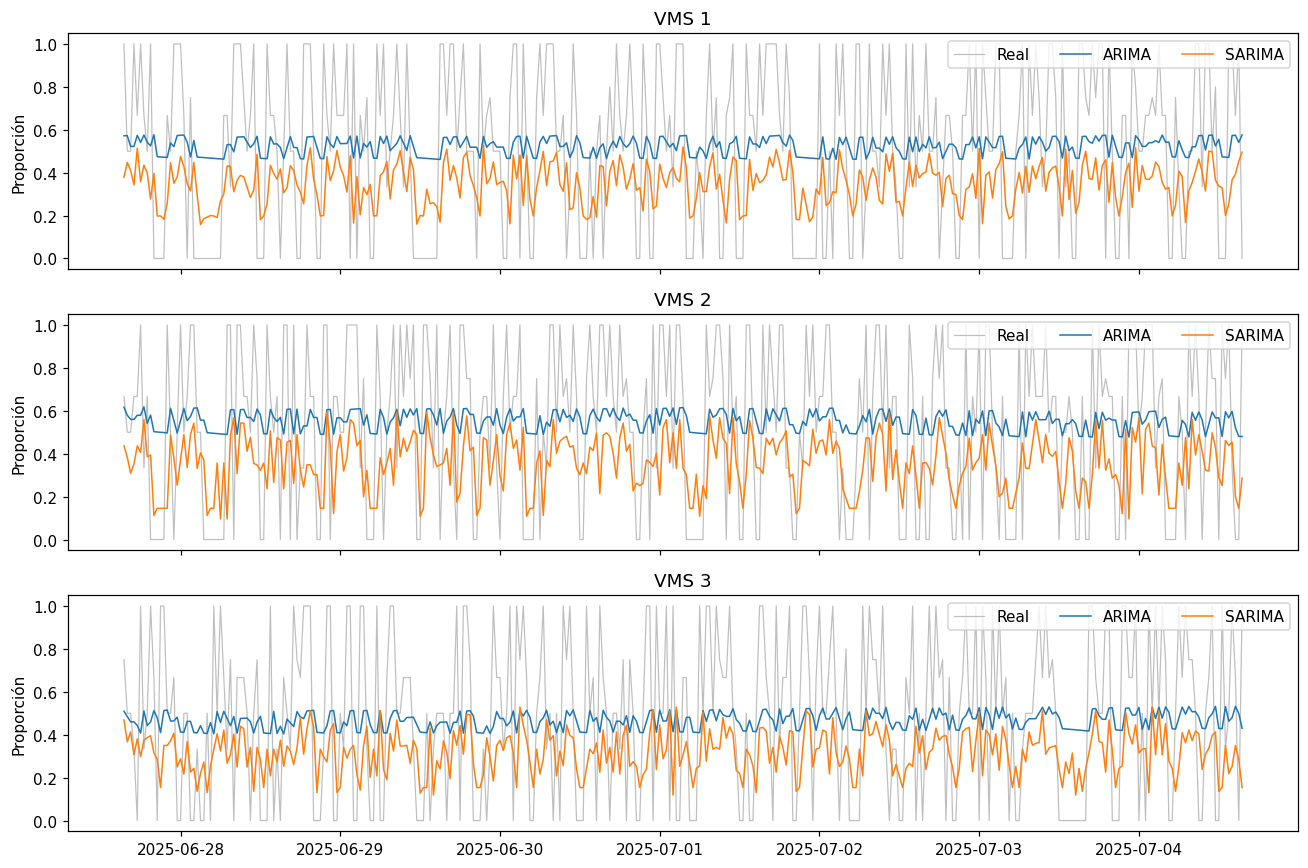

In [ ]:
def graficar_pronostico_siete_dias(pred_test, robots, series):
    fig, axes = plt.subplots(len(robots), 1, figsize=(12, 8), sharex=True)
    fin_grafica = INICIO_TEST + pd.Timedelta(days=7)
    for ax, robot in zip(axes, robots):
        real = series[robot].loc[INICIO_TEST:fin_grafica]
        ax.plot(real.index, real, color="0.75", linewidth=0.8, label="Real")
        for familia in ["ARIMA", "SARIMA"]:
            grupo = pred_test.loc[
                pred_test["ms"].eq(robot)
                & pred_test["Modelo"].eq(familia)
                & pred_test["bloque_tiempo"].le(fin_grafica)
            ]
            ax.plot(grupo["bloque_tiempo"], grupo["Prediccion"], linewidth=1, label=familia)
        ax.set(title=robot, ylabel="Proporción", ylim=(-0.05, 1.05))
        ax.legend(loc="upper right", ncol=3)
    plt.tight_layout()
    return fig


fig = graficar_pronostico_siete_dias(pred_test, robots, series)
plt.show()
plt.close(fig)

Observamos que ambos modelos suavizan los cambios bruscos y que SARIMA oscila más. Consideramos esta limitación al explicar los errores y leer una predicción puntual.

Mostramos ejemplos individuales de predicción continua y de su conversión a una etiqueta binaria.

In [ ]:
display(
    pred_test[
        ["Modelo", "ms", "bloque_tiempo", "Real", "Prediccion", "Cola_real", "Cola_predicha"]
    ]
    .groupby(["Modelo", "ms"], sort=False)
    .head(3)
)

,Modelo,ms,bloque_tiempo,Real,Prediccion,Cola_real,Cola_predicha
0,ARIMA,VMS 1,2025-06-27 15:30:00,1,0.5717,1,1
1,ARIMA,VMS 1,2025-06-27 16:00:00,0.5,0.5728,0,1
2,ARIMA,VMS 1,2025-06-27 16:30:00,0.5,0.5222,0,1
8993,SARIMA,VMS 1,2025-06-27 15:30:00,1,0.3789,1,1
8994,SARIMA,VMS 1,2025-06-27 16:00:00,0.5,0.448,0,1
8995,SARIMA,VMS 1,2025-06-27 16:30:00,0.5,0.4108,0,1
17986,ARIMA,VMS 2,2025-06-27 15:30:00,0.6667,0.6168,1,1
17987,ARIMA,VMS 2,2025-06-27 16:00:00,0.5,0.5791,0,1
17988,ARIMA,VMS 2,2025-06-27 16:30:00,0.5,0.56,0,1
26979,SARIMA,VMS 2,2025-06-27 15:30:00,0.6667,0.437,1,1


Convertimos cada pronóstico en etiqueta con el umbral predictivo de su robot. Distinguimos esta regla del 0.5 observado para no confundir estimación y verdad real.

### 2.9 Pronósticos futuros

Pronosticamos cuatro bloques desde el final del archivo.
Diferenciamos este horizonte de varios pasos de la prueba a un paso actualizada con observaciones.

Para los bloques futuros todavía no tenemos nuevas observaciones. Por eso hacemos varios pasos desde el último estado conocido.
Distinguimos este uso de la prueba a un paso, donde sí actualizamos con lo observado.

In [ ]:
def predecir_futuro(paquetes, escaladores_guardados, familia, robot, pasos=4):
    if not isinstance(pasos, int) or not 1 <= pasos <= 48:
        raise ValueError("Usa entre 1 y 48 bloques futuros.")
    paquete = paquetes[familia, robot]
    pronostico = paquete["resultado"].forecast(steps=pasos)
    crudas = (
        escaladores_guardados[robot]
        .inverse_transform(pronostico.to_numpy().reshape(-1, 1))
        .ravel()
    )
    estimaciones = np.clip(crudas, 0, 1)
    return pd.DataFrame(
        {
            "Modelo": familia,
            "ms": robot,
            "bloque_tiempo": pronostico.index,
            "Horizonte_min": 30 * np.arange(1, pasos + 1),
            "Prediccion": estimaciones,
            "Umbral": paquete["umbral"],
            "Posible_cola": (estimaciones >= paquete["umbral"]).astype(int),
        }
    )

Pronosticamos cuatro bloques desde el final del archivo con los estados actualizados hasta la última observación.

In [ ]:
def pronosticar_futuro(escaladores, estados_actualizados, robots):
    predicciones_futuras = pd.concat(
        [
            predecir_futuro(
                estados_actualizados, escaladores, familia, robot, PASOS_FUTUROS
            )
            for familia in ["ARIMA", "SARIMA"]
            for robot in robots
        ],
        ignore_index=True,
    )
    return predicciones_futuras


predicciones_futuras = pronosticar_futuro(escaladores, estados_actualizados, robots)

Mostramos las predicciones de los próximos 30, 60, 90 y 120 minutos respecto al final del dataset.

In [ ]:
display(predicciones_futuras)

,Modelo,ms,bloque_tiempo,Horizonte_min,Prediccion,Umbral,Posible_cola
0,ARIMA,VMS 1,2026-01-01 00:00:00,30,0.7237,0.35,1
1,ARIMA,VMS 1,2026-01-01 00:30:00,60,0.7295,0.35,1
2,ARIMA,VMS 1,2026-01-01 01:00:00,90,0.7301,0.35,1
3,ARIMA,VMS 1,2026-01-01 01:30:00,120,0.7301,0.35,1
4,ARIMA,VMS 2,2026-01-01 00:00:00,30,0.6884,0.38,1
5,ARIMA,VMS 2,2026-01-01 00:30:00,60,0.653,0.38,1
6,ARIMA,VMS 2,2026-01-01 01:00:00,90,0.649,0.38,1
7,ARIMA,VMS 2,2026-01-01 01:30:00,120,0.6486,0.38,1
8,ARIMA,VMS 3,2026-01-01 00:00:00,30,0.5456,0.37,1
9,ARIMA,VMS 3,2026-01-01 00:30:00,60,0.6009,0.37,1


Etiquetamos como positivos los cuatro bloques pronosticados. Los presentamos como ejemplos desde el final del archivo y no comprobamos su exactitud sin observaciones futuras.

### 2.10 Conclusión

Obtenemos F1 = 0.7304 con ARIMA y 0.7412 con SARIMA, frente a 0.7304 de siempre cola.
Estimamos MAE = 0.3179 y 0.3728, respectivamente, y reconocemos una ventaja clasificatoria pequeña de SARIMA.